# 03 — Carrier Modulation

Phase 1, steps 5-6: generate each band's carrier and multiply it by that
band's envelope — the core vocoder step.

Two carrier types (runtime toggle: `noise` | `tone`):

- **Noise carrier**: white noise passed through the *same* bandpass filter
  used to split that channel, so its energy sits in the same band as the
  original signal there.
- **Tone carrier**: a pure sine at the band's center frequency.

Multiplying envelope x carrier imposes the original signal's amplitude
pattern onto a synthetic signal that only has the frequency information a
CI electrode can actually deliver (which band fired, how hard) — not the
fine pitch/timbre inside that band. This notebook rebuilds the filterbank
+ envelopes from `01`/`02`, generates both carrier types, modulates, and
listens to individual modulated bands before summing anything (that's
`04_full_pipeline_compare.ipynb`).

In [10]:
import numpy as np
import soundfile as sf
from scipy import signal
import matplotlib.pyplot as plt
from IPython.display import Audio, display

TARGET_SR = 16000
RNG = np.random.default_rng(0)  # fixed seed so carrier noise is reproducible across runs

## Rebuild filterbank + envelope setup from 01 & 02

Same functions as before, not re-explained here — see the previous two
notebooks for the reasoning. This just gets us back to "N bands, each
with its envelope extracted" so there's something to modulate.

In [11]:
def load_raw(path):
    audio, native_sr = sf.read(path)
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    return audio.astype(np.float32), native_sr


def resample_to(audio, native_sr, target_sr):
    if native_sr == target_sr:
        return audio
    n_samples = int(len(audio) * target_sr / native_sr)
    return signal.resample(audio, n_samples).astype(np.float32)


def design_filterbank(n_channels, sr, f_min=200, f_max=7000, order=4):
    """Return (sos_list, edges, centers) for N log-spaced Butterworth bandpass filters."""
    edges = np.logspace(np.log10(f_min), np.log10(f_max), n_channels + 1)
    centers = np.sqrt(edges[:-1] * edges[1:])

    nyquist = sr / 2
    sos_list = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        sos = signal.butter(order, [lo / nyquist, hi / nyquist], btype="bandpass", output="sos")
        sos_list.append(sos)

    return sos_list, edges, centers


def split_into_bands(audio, sos_list):
    return [signal.sosfiltfilt(sos, audio) for sos in sos_list]


def envelope_rectify_lowpass(band, sr, cutoff=400, order=4):
    rectified = np.abs(band)
    nyquist = sr / 2
    sos = signal.butter(order, cutoff / nyquist, btype="lowpass", output="sos")
    return signal.sosfiltfilt(sos, rectified)


def extract_envelopes(bands, sr, cutoff=400, order=4):
    return [envelope_rectify_lowpass(b, sr, cutoff, order) for b in bands]


speech_raw, speech_native_sr = load_raw("../samples/speech.wav")
music_raw, music_native_sr = load_raw("../samples/music.wav")

speech = resample_to(speech_raw, speech_native_sr, TARGET_SR)
music = resample_to(music_raw, music_native_sr, TARGET_SR)
sr = TARGET_SR

N_CHANNELS = 8
ENV_CUTOFF = 400
filterbank, edges, centers = design_filterbank(N_CHANNELS, sr)

speech_bands = split_into_bands(speech, filterbank)
music_bands = split_into_bands(music, filterbank)

speech_envelopes = extract_envelopes(speech_bands, sr, ENV_CUTOFF)
music_envelopes = extract_envelopes(music_bands, sr, ENV_CUTOFF)

print(f"{N_CHANNELS} bands, {len(speech_envelopes)} envelopes ready @ {sr} Hz")

8 bands, 8 envelopes ready @ 16000 Hz


## Noise carrier

White noise filtered through the band's own `sos` — same filter used to
split the signal into that band in the first place, so the carrier's
energy lines up with the channel it's standing in for.

In [12]:
def generate_noise_carrier(sos, length, sr, rng):
    white = rng.standard_normal(length).astype(np.float32)
    return signal.sosfiltfilt(sos, white)


speech_noise_carriers = [
    generate_noise_carrier(sos, len(speech), sr, RNG) for sos in filterbank
]
print(f"{len(speech_noise_carriers)} noise carriers generated, length {len(speech_noise_carriers[0])}")

8 noise carriers generated, length 41920


## Tone carrier

A pure sine at each band's center frequency (geometric mean of its edges,
from `design_filterbank`).

In [13]:
def generate_tone_carrier(center_freq, length, sr):
    t = np.arange(length) / sr
    return np.sin(2 * np.pi * center_freq * t).astype(np.float32)


speech_tone_carriers = [
    generate_tone_carrier(c, len(speech), sr) for c in centers
]
print(f"{len(speech_tone_carriers)} tone carriers generated at centers (Hz): {np.round(centers).astype(int)}")

8 tone carriers generated at centers (Hz): [ 250  390  608  947 1478 2305 3594 5605]


## Modulate: envelope x carrier

The core step — elementwise multiply. Do it for both carrier types on
every band so we can compare them.

In [14]:
def modulate(envelope, carrier):
    return envelope * carrier


speech_modulated_noise = [
    modulate(env, car) for env, car in zip(speech_envelopes, speech_noise_carriers)
]
speech_modulated_tone = [
    modulate(env, car) for env, car in zip(speech_envelopes, speech_tone_carriers)
]

print(f"{len(speech_modulated_noise)} bands modulated (noise), {len(speech_modulated_tone)} bands modulated (tone)")

8 bands modulated (noise), 8 bands modulated (tone)


## Listen to individual modulated bands

Each one is a preview of a single CI electrode's contribution. The noise
version should sound like a hiss/rumble that swells and fades with
speech's rhythm; the tone version should sound like a buzzy whistle doing
the same. Band 0 (low) vs. the highest band should sound clearly
different in pitch/texture even though they're carrying the same kind of
envelope.

In [15]:
print("speech — band 0 modulated, noise carrier:")
display(Audio(speech_modulated_noise[0], rate=sr))
print("speech — band 0 modulated, tone carrier:")
display(Audio(speech_modulated_tone[0], rate=sr))

print(f"speech — band {N_CHANNELS - 1} modulated, noise carrier:")
display(Audio(speech_modulated_noise[-1], rate=sr))
print(f"speech — band {N_CHANNELS - 1} modulated, tone carrier:")
display(Audio(speech_modulated_tone[-1], rate=sr))

speech — band 0 modulated, noise carrier:


speech — band 0 modulated, tone carrier:


speech — band 7 modulated, noise carrier:


speech — band 7 modulated, tone carrier:


## Spectral check

Confirm each modulated band's energy still sits between its designed
edges (dashed lines) — modulation by a slow envelope shouldn't spread
energy outside the band the carrier was built for.

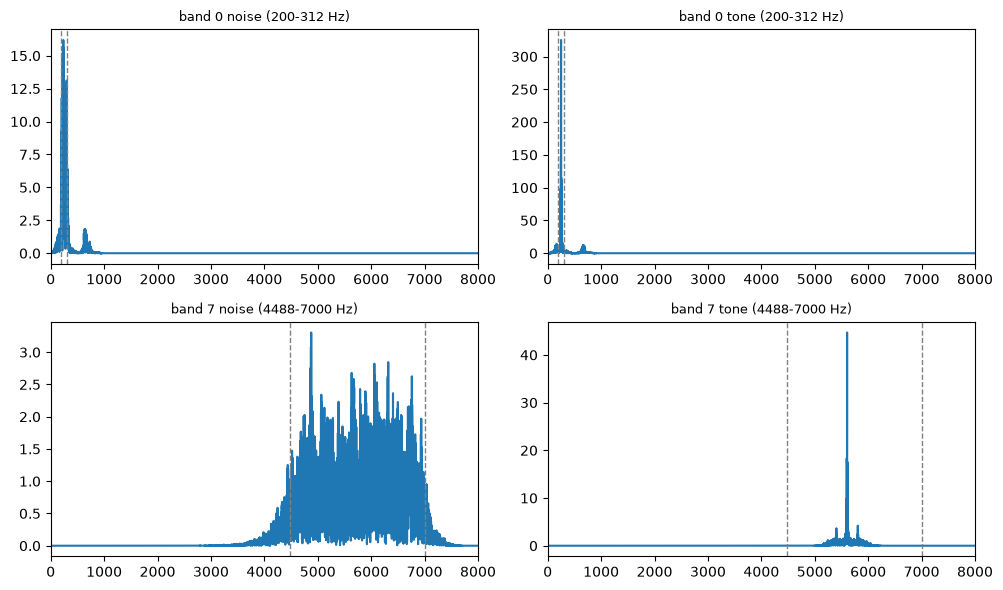

In [16]:
def plot_modulated_spectrum(sig, lo, hi, sr, ax, title):
    freqs = np.fft.rfftfreq(len(sig), d=1 / sr)
    mag = np.abs(np.fft.rfft(sig))
    ax.plot(freqs, mag)
    ax.axvline(lo, color="gray", linestyle="--", linewidth=1)
    ax.axvline(hi, color="gray", linestyle="--", linewidth=1)
    ax.set_xlim(0, sr / 2)
    ax.set_title(title, fontsize=9)


fig, axes = plt.subplots(2, 2, figsize=(10, 6))
plot_modulated_spectrum(
    speech_modulated_noise[0], edges[0], edges[1], sr, axes[0, 0],
    f"band 0 noise ({edges[0]:.0f}-{edges[1]:.0f} Hz)",
)
plot_modulated_spectrum(
    speech_modulated_tone[0], edges[0], edges[1], sr, axes[0, 1],
    f"band 0 tone ({edges[0]:.0f}-{edges[1]:.0f} Hz)",
)
plot_modulated_spectrum(
    speech_modulated_noise[-1], edges[-2], edges[-1], sr, axes[1, 0],
    f"band {N_CHANNELS - 1} noise ({edges[-2]:.0f}-{edges[-1]:.0f} Hz)",
)
plot_modulated_spectrum(
    speech_modulated_tone[-1], edges[-2], edges[-1], sr, axes[1, 1],
    f"band {N_CHANNELS - 1} tone ({edges[-2]:.0f}-{edges[-1]:.0f} Hz)",
)
plt.tight_layout()
plt.show()

## Wrap for the next notebook

Package carrier generation + modulation as `generate_carriers` /
`modulate_bands` so `04_full_pipeline_compare.ipynb` can call straight
through from envelopes to modulated bands for either carrier type.

In [17]:
def generate_carriers(carrier_type, filterbank, centers, length, sr, rng):
    if carrier_type == "noise":
        return [generate_noise_carrier(sos, length, sr, rng) for sos in filterbank]
    elif carrier_type == "tone":
        return [generate_tone_carrier(c, length, sr) for c in centers]
    else:
        raise ValueError(f"unknown carrier_type: {carrier_type!r}")


def modulate_bands(envelopes, carriers):
    return [modulate(env, car) for env, car in zip(envelopes, carriers)]


# quick round-trip check using the wrapped functions
_carriers = generate_carriers("tone", filterbank, centers, len(speech), sr, RNG)
_modulated = modulate_bands(speech_envelopes, _carriers)
print(f"wrapped functions produced {len(_modulated)} modulated bands (tone)")

wrapped functions produced 8 modulated bands (tone)
